<h2 style='color:blue' align="center">KNN (K Nearest Neighbors) Classification: Machine Tutorial Using Python Sklearn</h2>

<a id="s1"></a>
# 1️⃣ What is KNN?

### 🧠 The idea in one sentence
> **"Tell me who your neighbours are, and I'll tell you who you are."**

Imagine you move to a new city and want to guess whether a restaurant is good. You ask the **K** people living closest to it. If most of them say *"good"*, you guess *good*. That is exactly KNN.

KNN is a **supervised** learning algorithm: we give it examples **with the correct answers (labels)**, and it uses them to label new, unseen examples.

<p align="center">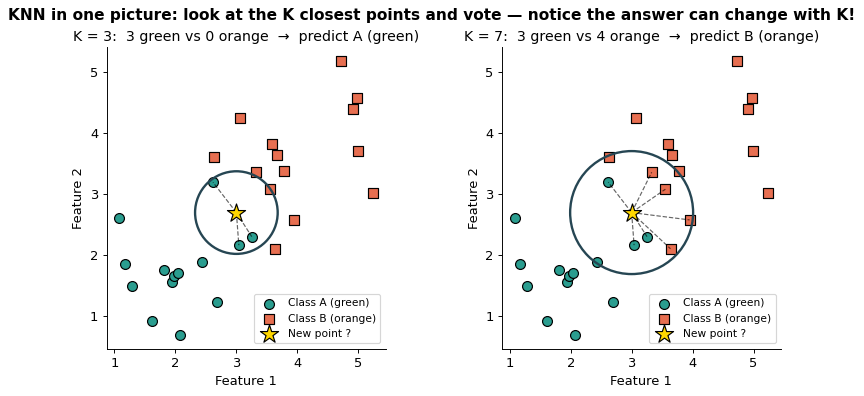<br><em>The gold star is a new point. With K = 3 its neighbours vote green; with K = 7 they vote orange. K matters!</em></p>

### 🧠 The algorithm — only 4 steps
To predict the class of a new point $x_{new}$:

1. **Choose K** — how many neighbours to consult (e.g. 3, 5, 7).
2. **Measure the distance** from $x_{new}$ to *every* point in the training data.
3. **Pick the K closest** points (the "nearest neighbours").
4. **Vote** — the most common class among those K neighbours is the prediction.

📐 Written as a formula, the prediction is the class $c$ that appears most often among the neighbours $N_K(x_{new})$:

$$\hat{y} = \underset{c}{\arg\max} \sum_{i \in N_K(x_{new})} \mathbb{1}(y_i = c)$$

Here $\mathbb{1}(y_i = c)$ is **1** if neighbour $i$ belongs to class $c$, otherwise **0** — so the sum simply *counts votes*.

### 🧠 KNN is a "lazy learner"
Most algorithms learn an equation during training. KNN does **not** — "training" just means **storing** the data. All the work happens at prediction time. That makes training instant but prediction slow on huge datasets.



<a id="s2"></a>
# 2️⃣ Measuring distance — what does "nearest" mean?

"Nearest" needs a way to measure distance. The two most common are:

<p align="center">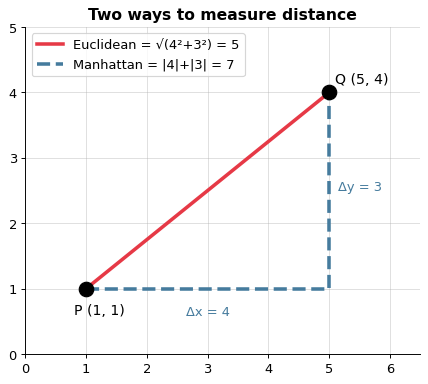</p>

### 📐 Euclidean distance (straight line — the default)
For two points $p = (p_1, \dots, p_n)$ and $q = (q_1, \dots, q_n)$:

$$d_{Euclidean}(p, q) = \sqrt{\sum_{i=1}^{n} (p_i - q_i)^2}$$

*In 2-D this is just Pythagoras' theorem:* $\sqrt{4^2 + 3^2} = \sqrt{25} = 5$.

### 📐 Manhattan distance ("city-block" — walking along streets)
$$d_{Manhattan}(p, q) = \sum_{i=1}^{n} |p_i - q_i|$$

For the picture: $|5-1| + |4-1| = 4 + 3 = 7$.

### 📐 Minkowski distance (the general family)
$$d_{Minkowski}(p, q) = \left(\sum_{i=1}^{n} |p_i - q_i|^{\,p}\right)^{1/p}$$

* $p = 1$ → Manhattan  * $p = 2$ → Euclidean (scikit-learn's default: `metric='minkowski', p=2`)

▶️ Let's check the numbers from the picture with code.

<a id="s3"></a>
# 3️⃣ Worked example — KNN by hand ✏️

Before using any library, let's do KNN with pencil and paper. We have 6 flowers with two measurements and a known species:

| Flower | Petal length (cm) | Petal width (cm) | Species |
|:-:|:-:|:-:|:-:|
| A | 1.4 | 0.2 | setosa |
| B | 1.3 | 0.3 | setosa |
| C | 4.5 | 1.5 | versicolor |
| D | 4.0 | 1.3 | versicolor |
| E | 5.8 | 2.2 | virginica |
| F | 5.1 | 1.9 | virginica |

**New flower:** petal length = **4.8**, petal width = **1.7**. What species is it? Use **K = 3**.

**Step 1 – distances** (Euclidean):

| Flower | Calculation | Distance |
|:-:|:--|:-:|
| A | $\sqrt{(4.8-1.4)^2 + (1.7-0.2)^2} = \sqrt{11.56+2.25}$ | 3.72 |
| B | $\sqrt{(4.8-1.3)^2 + (1.7-0.3)^2} = \sqrt{12.25+1.96}$ | 3.77 |
| C | $\sqrt{(4.8-4.5)^2 + (1.7-1.5)^2} = \sqrt{0.09+0.04}$ | **0.36** |
| D | $\sqrt{(4.8-4.0)^2 + (1.7-1.3)^2} = \sqrt{0.64+0.16}$ | **0.89** |
| E | $\sqrt{(4.8-5.8)^2 + (1.7-2.2)^2} = \sqrt{1.00+0.25}$ | 1.12 |
| F | $\sqrt{(4.8-5.1)^2 + (1.7-1.9)^2} = \sqrt{0.09+0.04}$ | **0.36** |

**Step 2 – the 3 nearest:** C (0.36), F (0.36), D (0.89)

**Step 3 – vote:** versicolor 🟦🟦 vs virginica 🟥 → **Prediction: versicolor** ✅

▶️ Now let the computer verify our hand calculation:

In [35]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score
import numpy as np
import seaborn as sns
iris = load_iris()

[![iris-petal-sepal.png](https://i.postimg.cc/5ts6F3BK/iris-petal-sepal.png)](https://postimg.cc/Z9yTG6D6)

# view feature_names

In [36]:
iris.feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

# view the target_names

In [37]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [38]:
df = pd.DataFrame(iris.data,columns=iris.feature_names)
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


# Add iris.target to df['target']

In [39]:
df["target"]=iris.target

In [40]:
df[df.target==0].head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [41]:
df[df.target==2].head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
100,6.3,3.3,6.0,2.5,2
101,5.8,2.7,5.1,1.9,2
102,7.1,3.0,5.9,2.1,2
103,6.3,2.9,5.6,1.8,2
104,6.5,3.0,5.8,2.2,2


In [42]:
df['flower_name'] =df.target.apply(lambda x: iris.target_names[x])
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,flower_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [43]:
df[45:55]

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,flower_name
45,4.8,3.0,1.4,0.3,0,setosa
46,5.1,3.8,1.6,0.2,0,setosa
47,4.6,3.2,1.4,0.2,0,setosa
48,5.3,3.7,1.5,0.2,0,setosa
49,5.0,3.3,1.4,0.2,0,setosa
50,7.0,3.2,4.7,1.4,1,versicolor
51,6.4,3.2,4.5,1.5,1,versicolor
52,6.9,3.1,4.9,1.5,1,versicolor
53,5.5,2.3,4.0,1.3,1,versicolor
54,6.5,2.8,4.6,1.5,1,versicolor


In [44]:
df0 = df[:50]
df1 = df[50:100]
df2 = df[100:]

In [45]:
import matplotlib.pyplot as plt
%matplotlib inline

**Sepal length vs Sepal Width (Setosa vs Versicolor)**

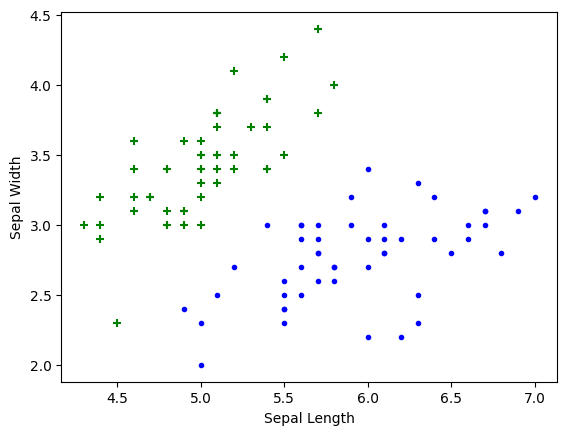

In [46]:
plt.xlabel('Sepal Length')
plt.ylabel('Sepal Width')
plt.scatter(df0['sepal length (cm)'], df0['sepal width (cm)'],color="green",marker='+')
plt.scatter(df1['sepal length (cm)'], df1['sepal width (cm)'],color="blue",marker='.')

**Petal length vs Pepal Width (Setosa vs Versicolor)**

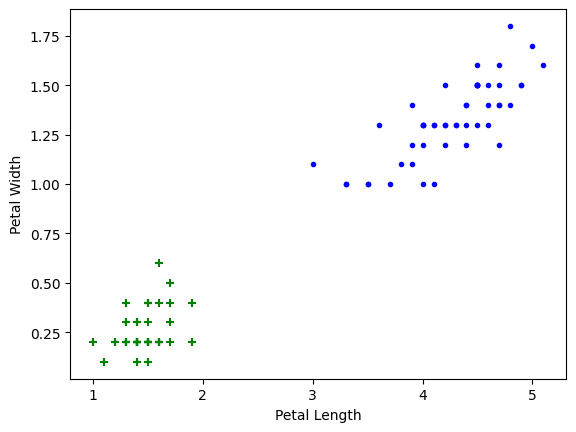

In [47]:
plt.xlabel('Petal Length')
plt.ylabel('Petal Width')
plt.scatter(df0['petal length (cm)'], df0['petal width (cm)'],color="green",marker='+')
plt.scatter(df1['petal length (cm)'], df1['petal width (cm)'],color="blue",marker='.')

**Train test split**

In [48]:
from sklearn.model_selection import train_test_split

# remove ['target','flower_name'] in df and prepare the X and Y
###### X = df.drop(['target','flower_name'], axis='columns')
###### y = df.target

In [49]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,flower_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [50]:
X=df.drop(["target","flower_name"],axis="columns")
y=df.target

In [51]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [52]:
len(X_train)

120

In [53]:
len(X_test)

30

**Create KNN (K Neighrest Neighbour Classifier)**

In [54]:
from sklearn.neighbors import KNeighborsClassifier
knn= KNeighborsClassifier(n_neighbors=5)

In [55]:
knn.fit(X_train,y_train)

KNeighborsClassifier()

In [56]:
knn.score(X_test, y_test)

1.0

In [57]:
# Predict the species of a new flower using the four Iris measurements
new_flower = [[4.8, 3.5, 1.5, 0.3]]
prediction = knn.predict(new_flower)
print("Predicted species:", iris.target_names[prediction[0]])

Predicted species: setosa


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


**Plot Confusion Matrix**

In [58]:
from sklearn.metrics import confusion_matrix
y_pred = knn.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
cm

array([[11,  0,  0],
       [ 0, 13,  0],
       [ 0,  0,  6]])

Text(58.222222222222214, 0.5, 'Truth')

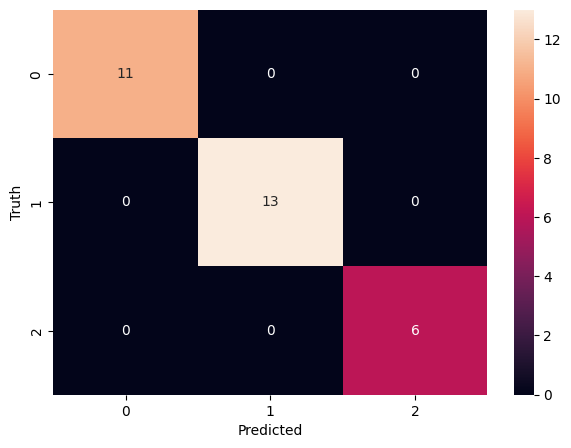

In [59]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sn
plt.figure(figsize=(7,5))
sn.heatmap(cm, annot=True)
plt.xlabel('Predicted')
plt.ylabel('Truth')

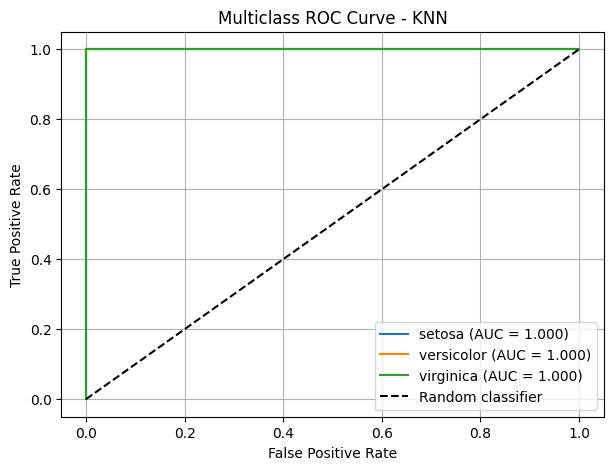

KNN Accuracy: 1.0
Macro AUC: 1.0


In [60]:
# Multiclass ROC curves (one-vs-rest)
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt

# Use the same train/test split as above
knn_roc = KNeighborsClassifier(n_neighbors=5)
knn_roc.fit(X_train, y_train)
y_prob = knn_roc.predict_proba(X_test)
y_test_bin = label_binarize(y_test, classes=knn_roc.classes_)

plt.figure(figsize=(7, 5))
for i, name in enumerate(knn_roc.classes_):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
    plt.plot(fpr, tpr, label=f"{iris.target_names[name]} (AUC = {auc(fpr, tpr):.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curve - KNN")
plt.legend()
plt.grid(True)
plt.show()

print("KNN Accuracy:", round(knn_roc.score(X_test, y_test), 3))
print("Macro AUC:", round(
    roc_auc_score(y_test, y_prob, multi_class="ovr", average="macro"), 3
))

**Print classification report for precesion, recall and f1-score for each classes**

In [61]:
from sklearn.metrics import classification_report

# Recalculate predictions from the classifier used in the main KNN section
y_pred = knn.predict(X_test)
print(classification_report(y_test, y_pred, target_names=iris.target_names, zero_division=0))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        11
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00         6

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



Bulding KNN from Scrath

# Step 1: Load Dataset


In [62]:
iris = load_iris()
X = iris.data[:, :2]   # take first 2 features (for visualization: Sepal Length & Sepal Width)
y = iris.target
target_names = iris.target_names

In [63]:
# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# euclidean distance

In [64]:
def euclidean_distance(a,b):
    return np.sqrt(np.sum((a-b)**2))


## Pseudocode: K-Nearest Neighbors (KNN) Prediction

**Algorithm: KNN_Predict**

**Input:**  
- Training data `X_train`
- Training labels `y_train`
- Test data `X_test`
- Number of neighbors `k`

**Output:**  
- Predicted labels `predictions`

### Pseudocode

```text
BEGIN

    Initialize predictions as an empty list

    FOR each test_point in X_test DO

        Initialize distances as an empty list

        FOR each training_point in X_train DO
            distance ← Euclidean_Distance(test_point, training_point)
            Add distance to distances
        END FOR

        nearest_indices ← indices of k smallest values in distances

        nearest_labels ← labels of training points
                          corresponding to nearest_indices

        predicted_label ← most frequent label in nearest_labels

        Add predicted_label to predictions

    END FOR

    RETURN predictions

END


In [65]:
def knn_predict(X_train, y_train, X_test, k=3):
    predictions = []

    for test_point in X_test:
        # Calculate distance from the test point to each training point
        distances = [euclidean_distance(test_point, x) for x in X_train]

        # Find the k nearest neighbours
        k_indices = np.argsort(distances)[:k]
        k_labels = [y_train[i] for i in k_indices]

        # Select the most common label
        label = max(set(k_labels), key=k_labels.count)
        predictions.append(label)

    return np.array(predictions)

# Step 3: Train and predict
k = 5
y_pred = knn_predict(X_train, y_train, X_test, k)

# Step 4: Evaluate
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=target_names))

Accuracy: 0.7777777777777778

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       0.64      0.54      0.58        13
   virginica       0.60      0.69      0.64        13

    accuracy                           0.78        45
   macro avg       0.75      0.74      0.74        45
weighted avg       0.78      0.78      0.78        45



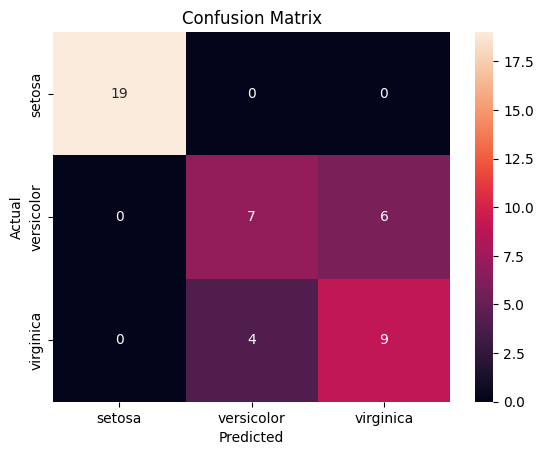

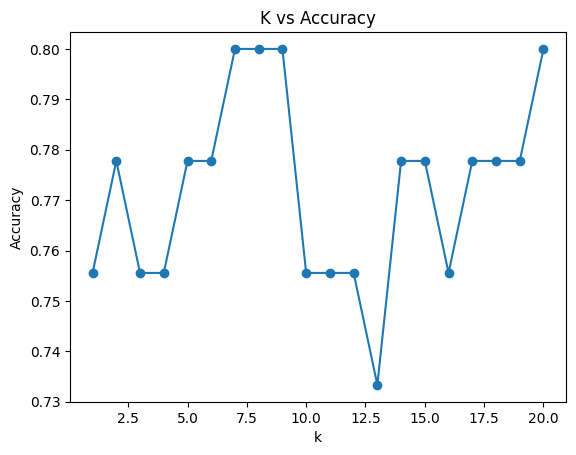

In [66]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", xticklabels=target_names, yticklabels=target_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Accuracy for different values of k
k_values = range(1, 21)
acc_scores = []

for k in k_values:
    y_pred_k = knn_predict(X_train, y_train, X_test, k)
    acc_scores.append(accuracy_score(y_test, y_pred_k))

plt.plot(k_values, acc_scores, marker="o")
plt.xlabel("k")
plt.ylabel("Accuracy")
plt.title("K vs Accuracy")
plt.show()

<a id="s9"></a>
# 9️⃣ Choosing the best K

<p align="center">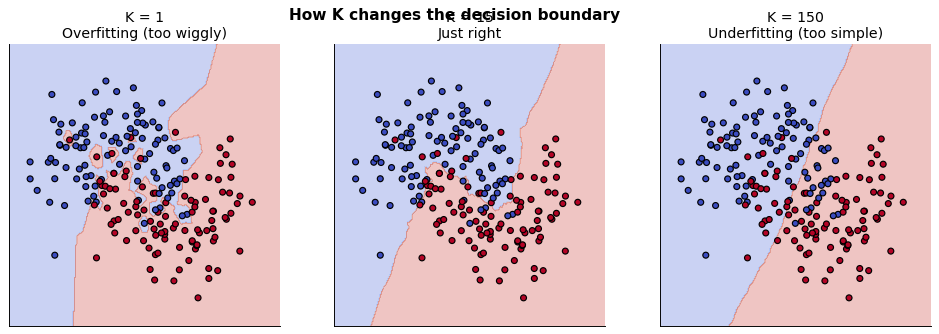</p>

| K | Behaviour | Problem |
|---|---|---|
| Very small (K = 1) | follows every single point, even noise | **Overfitting** – high variance |
| Very large (K ≈ n) | always predicts the majority class | **Underfitting** – high bias |
| In between | smooth but flexible boundary | ✅ |

**Rules of thumb:** start with $K \approx \sqrt{n_{train}}$ (here $\sqrt{120} \approx 11$), prefer odd K, and then **test several values**.

▶️ Let's try K = 1 … 30 and plot the test accuracy:

<a id="s15"></a>
# 1️⃣5️⃣ ✍️ Practice exercise — handwritten digits

Now apply everything to a new dataset on your own. `load_digits()` contains **1 797 images** of handwritten digits 0–9. Each image is **8 × 8 pixels = 64 features** (pixel brightness 0–16).

### Your tasks
1. Load the digits dataset and look at some images.
2. Split into train/test sets (`test_size=0.2`, `random_state=10`).
3. Train a KNN classifier. Try different values of K
4. Plot the **confusion matrix**. Which digits are confused most often?
5. Print the **classification report**. Which digit has the lowest F1-score?

▶️ Here's a starter to visualise the data:

Data shape: (1797, 64)


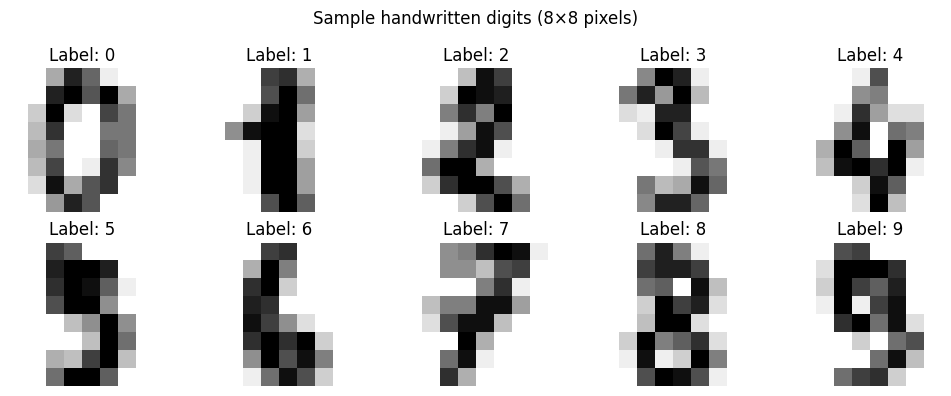

In [67]:
# Task 1: Load the digits dataset and visualize sample images
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt

digits = load_digits()
print("Data shape:", digits.data.shape)  # 1,797 samples and 64 pixel features

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for ax, image, label in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(image, cmap="gray_r")
    ax.set_title(f"Label: {label}")
    ax.axis("off")
plt.suptitle("Sample handwritten digits (8×8 pixels)")
plt.tight_layout()
plt.show()

In [69]:
# Task 2
X_digits = digits.data
y_digits = digits.target

X_digits_train, X_digits_test, y_digits_train, y_digits_test = train_test_split(
    X_digits, y_digits, test_size=0.2, random_state=10
)

print("Training samples:", len(X_digits_train))
print("Testing samples:", len(X_digits_test))



Training samples: 1437
Testing samples: 360


In [73]:
# Task 3
k_values = [1, 3, 5, 7, 9]

for k in k_values:
    knn_digits = KNeighborsClassifier(n_neighbors=k)
    knn_digits.fit(X_digits_train, y_digits_train)
    y_digits_pred = knn_digits.predict(X_digits_test)
    print("Accuracy for k =", k, ":", accuracy_score(y_digits_test, y_digits_pred))

# Use k = 1 for the final evaluation (highest accuracy in this test)
knn_digits = KNeighborsClassifier(n_neighbors=1)
knn_digits.fit(X_digits_train, y_digits_train)
y_digits_pred = knn_digits.predict(X_digits_test)




Accuracy for k = 1 : 0.9888888888888889
Accuracy for k = 3 : 0.9888888888888889
Accuracy for k = 5 : 0.9861111111111112
Accuracy for k = 7 : 0.9861111111111112
Accuracy for k = 9 : 0.9833333333333333


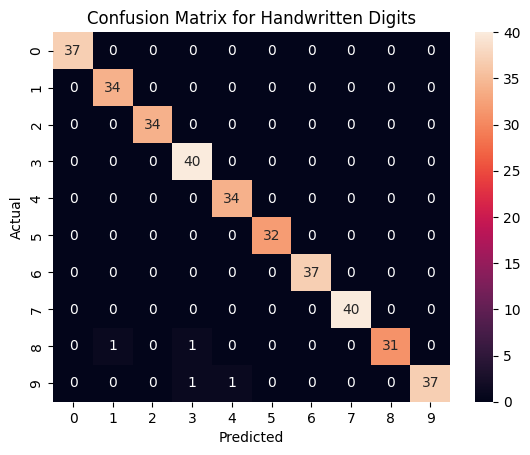

In [74]:
# Task 4
cm_digits = confusion_matrix(y_digits_test, y_digits_pred)
sns.heatmap(cm_digits, annot=True, fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Handwritten Digits")
plt.show()



In [76]:
# Task 5
print(classification_report(y_digits_test, y_digits_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        37
           1       0.97      1.00      0.99        34
           2       1.00      1.00      1.00        34
           3       0.95      1.00      0.98        40
           4       0.97      1.00      0.99        34
           5       1.00      1.00      1.00        32
           6       1.00      1.00      1.00        37
           7       1.00      1.00      1.00        40
           8       1.00      0.94      0.97        33
           9       1.00      0.95      0.97        39

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360

